# Лабораторная работа №4: Нейронные сети и современные подходы

**Вариант №1** · датасет **IMDB Movie Reviews (50k)** · задача **бинарная классификация тональности** (2 класса)

Особенности варианта: длинные тексты, сбалансированные классы (25k positive / 25k negative).

Что требуется по варианту:

1. **Загрузка и предобработка текста** — нижний регистр, удаление пунктуации/HTML и стоп-слов.
2. **Baseline TF-IDF** — `TfidfVectorizer` (уни- и биграммы, `max_features=10000`) + логистическая регрессия,
   метрики accuracy / F1 / ROC-AUC.
3. **Статические эмбеддинги** — предобученные word-векторы, вектор документа усреднением слов, та же модель.
4. **Современные эмбеддинги** — `all-MiniLM-L6-v2` (Sentence-Transformers) + LogReg / LightGBM.
5. **Сравнение** методов в сводной таблице.
6. **Снижение размерности и визуализация** — PCA (до 50 компонент) → t-SNE и UMAP, анализ кластеров
   и разделимости классов.

Порядок работы: загрузка данных (под DVC) → EDA → предобработка → TF-IDF → GloVe (mean) →
Sentence-Transformers → сравнение → PCA/t-SNE/UMAP → выводы.

## 1. Импорты и настройки

In [1]:
%matplotlib inline
import gzip
import re
import tarfile
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, silhouette_score)
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

# Корень проекта ищем по наличию .git — ноутбук можно запускать из любой папки
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / '.git').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW_DIR = PROJECT_ROOT / 'src' / 'data' / 'raw'
INTERIM_DIR = PROJECT_ROOT / 'src' / 'data' / 'interim'
MODELS_DIR = PROJECT_ROOT / 'src' / 'models'
REPORTS_DIR = PROJECT_ROOT / 'src' / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
for _d in (DATA_RAW_DIR, INTERIM_DIR, MODELS_DIR, REPORTS_DIR, FIGURES_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    """Сохранить текущий рисунок в src/reports/figures и показать его в ноутбуке."""
    path = FIGURES_DIR / ('%s.png' % name)
    plt.savefig(path, dpi=120, bbox_inches='tight')
    plt.show()
    print('Рисунок сохранён:', path.relative_to(PROJECT_ROOT))


def fmt_mb(n_bytes):
    return '%.1f MB' % (n_bytes / 1e6)


def download_file(url, dest):
    """Скачать файл, если его ещё нет (идемпотентно)."""
    if dest.exists() and dest.stat().st_size > 0:
        print('Файл уже есть: %s (%s)' % (dest.name, fmt_mb(dest.stat().st_size)))
        return dest
    print('Скачиваем %s ...' % url)
    tmp = Path(str(dest) + '.part')
    urllib.request.urlretrieve(url, tmp)
    tmp.replace(dest)
    print('Сохранено: %s (%s)' % (dest.name, fmt_mb(dest.stat().st_size)))
    return dest

## 2. Загрузка данных (IMDB Movie Reviews, 50k)

Датасет — классический **Large Movie Review Dataset (aclImdb)**: 50 000 рецензий (25 000 train / 25 000 test),
по 12 500 positive и 12 500 negative в каждой части. Берём его из первоисточника (Stanford), архив кэшируем
в `src/data/raw`, а разобранный датасет складываем в `src/data/raw/imdb_reviews.csv` — этот CSV версионируется
**DVC** (`dvc add src/data/raw/imdb_reviews.csv`).

In [2]:
IMDB_URL = 'https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz'
IMDB_ARCHIVE = DATA_RAW_DIR / 'aclImdb_v1.tar.gz'
IMDB_CSV = DATA_RAW_DIR / 'imdb_reviews.csv'


def parse_acl_imdb(archive, cache_csv):
    """Разобрать aclImdb в DataFrame(review, label, split); результат кэшируем в CSV."""
    if cache_csv.exists():
        print('Читаем разобранный датасет из кэша:', cache_csv.name)
        return pd.read_csv(cache_csv)
    rows = []
    with tarfile.open(archive, 'r:gz') as tar:
        for member in tar:  # однопроходное последовательное чтение архива (без обратных seek)
            if not member.isfile() or not member.name.endswith('.txt'):
                continue
            parts = member.name.split('/')
            if len(parts) != 4:  # нужен только aclImdb/<split>/<label>/<id>.txt
                continue
            _, split, label_name, _ = parts
            if label_name not in ('pos', 'neg'):
                continue
            text = tar.extractfile(member).read().decode('utf-8', errors='replace')
            rows.append((text, 1 if label_name == 'pos' else 0, split))
    df = pd.DataFrame(rows, columns=['review', 'label', 'split'])
    df.to_csv(cache_csv, index=False)
    print('Разобрано %d отзывов -> %s (%s)'
          % (len(df), cache_csv.name, fmt_mb(cache_csv.stat().st_size)))
    return df


t0 = time.perf_counter()
download_file(IMDB_URL, IMDB_ARCHIVE)
df = parse_acl_imdb(IMDB_ARCHIVE, IMDB_CSV)
print('Подготовка данных: %.1f c' % (time.perf_counter() - t0))
print('Форма датасета:', df.shape)
print(df.groupby(['split', 'label']).size().unstack())
df.head(3)

Файл уже есть: aclImdb_v1.tar.gz (84.1 MB)
Читаем разобранный датасет из кэша: imdb_reviews.csv


Подготовка данных: 0.6 c
Форма датасета: (50000, 3)
label      0      1
split              
test   12500  12500
train  12500  12500


,review,label,split
0,I love sci-fi and am willing to put up with a ...,0,test
1,"Worth the entertainment value of a rental, esp...",0,test
2,its a totally average film with a few semi-alr...,0,test


Баланс классов: positive (1) -> 0.500 | negative (0) -> 0.500
train: 25000 | test: 25000

Длина отзывов в словах:
        mean    50%     max
label                      
0      229.5  174.0  1522.0
1      232.8  172.0  2470.0

Пример отзыва (первые 300 символов):
I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogues, C


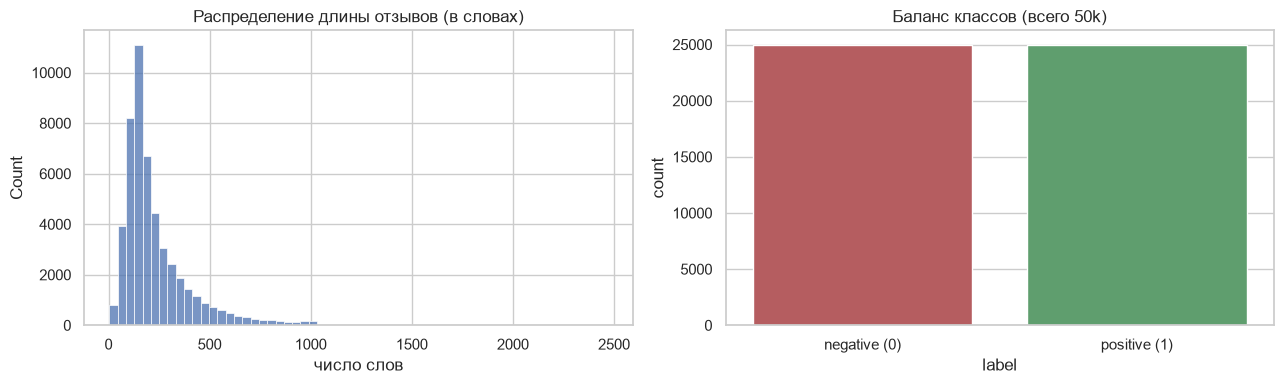

Рисунок сохранён: src\reports\figures\lab4_eda_lengths.png


In [3]:
df['n_chars'] = df['review'].str.len()
df['n_words'] = df['review'].str.count(r'\S+')

print('Баланс классов: positive (1) -> %.3f | negative (0) -> %.3f'
      % (df['label'].mean(), 1 - df['label'].mean()))
print('train: %d | test: %d' % ((df['split'] == 'train').sum(), (df['split'] == 'test').sum()))
print('\nДлина отзывов в словах:')
print(df.groupby('label')['n_words'].describe()[['mean', '50%', 'max']].round(1))
print('\nПример отзыва (первые 300 символов):')
print(df.loc[0, 'review'][:300].replace('\n', ' '))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['n_words'], bins=60, ax=axes[0], color='#4C72B0')
axes[0].set_title('Распределение длины отзывов (в словах)')
axes[0].set_xlabel('число слов')
sns.countplot(x='label', data=df, ax=axes[1], palette=['#C44E52', '#55A868'])
axes[1].set_title('Баланс классов (всего 50k)')
axes[1].set_xticklabels(['negative (0)', 'positive (1)'])
plt.tight_layout()
save_fig('lab4_eda_lengths')

## 3. Предобработка текста

Для «классических» методов (TF-IDF и усреднённые word-векторы) делаем очистку: нижний регистр, удаление
HTML-тегов `<br />`, пунктуации и цифр, отбрасываем слова короче двух букв и стоп-слова
(`ENGLISH_STOP_WORDS` из scikit-learn).

Для трансформеров (раздел 6) оставляем **сырой** текст: модели обучены на «естественном» тексте,
и удаление пунктуации/стоп-слов им только вредит.

In [4]:
BR_TAG = re.compile(r'<br\s*/?>')
NON_ALPHA = re.compile(r'[^a-z\s]')
WORD_RE = re.compile(r'[a-z]{2,}')
STOPWORDS = set(ENGLISH_STOP_WORDS)
MULTISPACE = re.compile(r'\s+')


def clean_text(text, remove_stopwords=True):
    """Нижний регистр -> убрать HTML -> только буквы -> токены >=2 букв -> минус стоп-слова."""
    text = text.lower()
    text = BR_TAG.sub(' ', text)
    text = NON_ALPHA.sub(' ', text)
    tokens = WORD_RE.findall(text)
    if remove_stopwords:
        tokens = [w for w in tokens if w not in STOPWORDS]
    return MULTISPACE.sub(' ', ' '.join(tokens)).strip()


t0 = time.perf_counter()
df['review_clean'] = [clean_text(t) for t in df['review']]
df['n_words_clean'] = df['review_clean'].str.count(r'\S+')
print('Очистка 50k отзывов: %.1f c' % (time.perf_counter() - t0))
print('Среднее число токенов: было %.1f -> стало %.1f'
      % (df['n_words'].mean(), df['n_words_clean'].mean()))
print('\nRAW  :', df.loc[0, 'review'][:200].replace('\n', ' '))
print('CLEAN:', df.loc[0, 'review_clean'][:200])

Очистка 50k отзывов: 4.2 c
Среднее число токенов: было 231.2 -> стало 105.9

RAW  : I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Bab
CLEAN: love sci fi willing lot sci fi movies tv usually underfunded appreciated misunderstood tried like really did good tv sci fi babylon star trek original silly prosthetics cheap cardboard sets stilted di


## 4. Baseline: TF-IDF + логистическая регрессия

Строим `TfidfVectorizer` (уни- и биграммы, `max_features=10000`, `min_df=2`, `sublinear_tf`) и обучаем
логистическую регрессию. Оцениваем на официальной тестовой части (25k отзывов) — accuracy, F1 и ROC-AUC.

In [5]:
train_df = df[df['split'] == 'train'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)
y_train = train_df['label'].to_numpy()
y_test = test_df['label'].to_numpy()

METRICS = {}


def evaluate(name, y_true, y_pred, y_proba, store=True):
    """Посчитать основные метрики бинарной классификации."""
    m = {
        'Метод': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba),
    }
    if store:
        METRICS[name] = m
    print('%-38s Acc=%.4f  F1=%.4f  ROC-AUC=%.4f'
          % (name, m['Accuracy'], m['F1'], m['ROC-AUC']))
    return m


tfidf_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=10000,
                              min_df=2, sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=1000, C=1.0, solver='liblinear',
                               random_state=SEED)),
])
t0 = time.perf_counter()
tfidf_pipe.fit(train_df['review_clean'], y_train)
print('Обучение TF-IDF + LogReg: %.1f c' % (time.perf_counter() - t0))
tfidf_metrics = evaluate('TF-IDF (uni+bi) + LogReg', y_test,
                         tfidf_pipe.predict(test_df['review_clean']),
                         tfidf_pipe.predict_proba(test_df['review_clean'])[:, 1])
Xtr_tfidf = tfidf_pipe.named_steps['tfidf'].transform(train_df['review_clean'])
print('TF-IDF (train): %s, n-грамм в словаре: %d'
      % (Xtr_tfidf.shape, len(tfidf_pipe.named_steps['tfidf'].vocabulary_)))

Обучение TF-IDF + LogReg: 8.7 c


TF-IDF (uni+bi) + LogReg               Acc=0.8866  F1=0.8872  ROC-AUC=0.9547


TF-IDF (train): (25000, 10000), n-грамм в словаре: 10000


In [6]:
vectorizer = tfidf_pipe.named_steps['tfidf']
coefs = pd.Series(tfidf_pipe.named_steps['clf'].coef_[0],
                  index=vectorizer.get_feature_names_out())
print('Топ-12 n-грамм, тянущих к positive:')
print(coefs.sort_values(ascending=False).head(12).round(3).to_string())
print('\nТоп-12 n-грамм, тянущих к negative:')
print(coefs.sort_values().head(12).round(3).to_string())

Топ-12 n-грамм, тянущих к positive:
great        6.598
excellent    6.083
best         5.105
perfect      4.844
wonderful    4.695
amazing      4.166
favorite     4.092
fun          3.672
today        3.604
loved        3.524
love         3.465
brilliant    3.325

Топ-12 n-грамм, тянущих к negative:
worst            -8.429
bad              -7.030
awful            -6.279
waste            -5.625
boring           -5.481
poor             -5.115
worse            -4.621
terrible         -4.380
poorly           -4.364
dull             -4.334
disappointment   -4.194
horrible         -4.056


## 5. Статические эмбеддинги: GloVe (слово-векторы) + усреднение

Берём предобученные статические word-векторы **GloVe 100d** (`glove-wiki-gigaword-100` — ровно тот датасет,
который отдаёт `gensim.downloader.load('glove-wiki-gigaword-100')`) и строим вектор документа **усреднением
векторов слов**, встретившихся в тексте.

> Технический нюанс: библиотека `gensim` под Python 3.14 не имеет готовых wheel-файлов и требует сборки
> C-расширений (компилятор MSVC), поэтому мы читаем **тот же самый файл датасета** из зеркала `gensim-data`
> напрямую и усредняем слова вручную — результат идентичен `gensim`-овому mean-pooling.

In [7]:
GLOVE_URL = ('https://github.com/piskvorky/gensim-data/releases/download/'
             'glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz')
GLOVE_PATH = DATA_RAW_DIR / 'glove-wiki-gigaword-100.gz'
GLOVE_CACHE = INTERIM_DIR / 'glove_doc_vectors.npz'


def load_word_vectors_gz(path, vocabulary):
    """Прочитать word2vec-текстовый формат (word v1 ... v100) из .gz; оставить только слова из словаря."""
    vectors = {}
    with gzip.open(path, 'rt', encoding='utf-8', errors='ignore') as f:
        n_words, dim = (int(x) for x in f.readline().split()[:2])
        for line in f:
            word, _, rest = line.partition(' ')
            if word in vocabulary:
                vectors[word] = np.asarray(rest.split(), dtype=np.float32)
    return vectors, dim


def mean_pool(texts, vectors, dim):
    """Вектор документа = среднее векторов известных слов. Возвращает (матрицу, покрытие слов)."""
    out = np.zeros((len(texts), dim), dtype=np.float32)
    known = total = 0
    for i, text in enumerate(texts):
        tokens = text.split()
        total += len(tokens)
        acc = np.zeros(dim, dtype=np.float32)
        cnt = 0
        for w in tokens:
            v = vectors.get(w)
            if v is not None:
                acc += v
                cnt += 1
        if cnt:
            out[i] = acc / cnt
        known += cnt
    return out, known / max(total, 1)


if GLOVE_CACHE.exists():
    _c = np.load(GLOVE_CACHE)
    Vtr_glove, Vte_glove, coverage = _c['train'], _c['test'], float(_c['coverage'])
    print('Загрузили кэш GloVe-эмбеддингов:', GLOVE_CACHE.name, Vtr_glove.shape)
else:
    download_file(GLOVE_URL, GLOVE_PATH)
    vocabulary = set()
    for t in df['review_clean']:
        vocabulary.update(t.split())
    print('Уникальных слов в корпусе: %d' % len(vocabulary))
    t0 = time.perf_counter()
    vectors, dim = load_word_vectors_gz(GLOVE_PATH, vocabulary)
    print('Загружено %d векторов GloVe размерности %d (%.1f c)'
          % (len(vectors), dim, time.perf_counter() - t0))
    t0 = time.perf_counter()
    Vtr_glove, cov_tr = mean_pool(train_df['review_clean'].tolist(), vectors, dim)
    Vte_glove, cov_te = mean_pool(test_df['review_clean'].tolist(), vectors, dim)
    coverage = cov_tr
    print('Усреднение слов: %.1f c' % (time.perf_counter() - t0))
    np.savez_compressed(GLOVE_CACHE, train=Vtr_glove, test=Vte_glove, coverage=coverage)
print('Покрытие слов словарём GloVe (train): %.1f%%' % (100 * coverage))

Загрузили кэш GloVe-эмбеддингов: glove_doc_vectors.npz (25000, 100)
Покрытие слов словарём GloVe (train): 99.2%


In [8]:
logreg_glove = LogisticRegression(max_iter=2000, C=1.0, random_state=SEED)
t0 = time.perf_counter()
logreg_glove.fit(Vtr_glove, y_train)
print('Обучение LogReg на GloVe-векторах: %.1f c' % (time.perf_counter() - t0))
glove_metrics = evaluate('GloVe-100 (mean) + LogReg', y_test,
                         logreg_glove.predict(Vte_glove),
                         logreg_glove.predict_proba(Vte_glove)[:, 1])

Обучение LogReg на GloVe-векторах: 0.1 c
GloVe-100 (mean) + LogReg              Acc=0.7988  F1=0.7976  ROC-AUC=0.8750


## 6. Современные эмбеддинги: Sentence-Transformers `all-MiniLM-L6-v2`

Модель `all-MiniLM-L6-v2` (6 слоёв, 384 признака, максимум 256 токенов) кодирует **весь документ**
контекстно, а не усредняет отдельные слова. Обучаем на полученных эмбеддингах логистическую регрессию
и LightGBM.

Длинные отзывы обрезаются до 256 токенов, а кодирование 50k текстов на CPU занимает ~20–25 минут —
поэтому эмбеддинги сохраняются в `src/data/interim` (`minilm_train.npy`, `minilm_test.npy`) и при повторном
запуске ноутбука просто загружаются с диска (полный повторный прогон — около двух минут).

In [9]:
import os

import torch
from sentence_transformers import SentenceTransformer

torch.set_num_threads(os.cpu_count() or 8)  # задействуем все ядра CPU

MINILM_NAME = 'all-MiniLM-L6-v2'
MINILM_TRAIN = INTERIM_DIR / 'minilm_train.npy'
MINILM_TEST = INTERIM_DIR / 'minilm_test.npy'


def encode_texts(texts, batch_size=64):
    """Закодировать тексты MiniLM (модель загружается один раз и переиспользуется)."""
    global _ST_MODEL
    try:
        model = _ST_MODEL
    except NameError:
        model = SentenceTransformer(MINILM_NAME, device='cpu')
        model.max_seq_length = 256
        _ST_MODEL = model
    return model.encode(texts, batch_size=batch_size, show_progress_bar=False,
                        convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)


if MINILM_TRAIN.exists():
    Etr_sbert = np.load(MINILM_TRAIN)
    print('Кэш train-эмбеддингов:', MINILM_TRAIN.name, Etr_sbert.shape)
else:
    t0 = time.perf_counter()
    Etr_sbert = encode_texts(train_df['review'].tolist())
    np.save(MINILM_TRAIN, Etr_sbert)
    print('Кодирование train (25k): %.1f c' % (time.perf_counter() - t0))

if MINILM_TEST.exists():
    Ete_sbert = np.load(MINILM_TEST)
    print('Кэш test-эмбеддингов:', MINILM_TEST.name, Ete_sbert.shape)
else:
    t0 = time.perf_counter()
    Ete_sbert = encode_texts(test_df['review'].tolist())
    np.save(MINILM_TEST, Ete_sbert)
    print('Кодирование test (25k): %.1f c' % (time.perf_counter() - t0))

print('Модель %s, эмбеддинги: train %s, test %s'
      % (MINILM_NAME, Etr_sbert.shape, Ete_sbert.shape))

Кэш train-эмбеддингов: minilm_train.npy (25000, 384)
Кэш test-эмбеддингов: minilm_test.npy (25000, 384)
Модель all-MiniLM-L6-v2, эмбеддинги: train (25000, 384), test (25000, 384)


In [10]:
logreg_sbert = LogisticRegression(max_iter=3000, C=1.0, random_state=SEED)
t0 = time.perf_counter()
logreg_sbert.fit(Etr_sbert, y_train)
print('Обучение LogReg на MiniLM: %.1f c' % (time.perf_counter() - t0))
sbert_metrics = evaluate('MiniLM (SBERT) + LogReg', y_test,
                         logreg_sbert.predict(Ete_sbert),
                         logreg_sbert.predict_proba(Ete_sbert)[:, 1])

from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8,
                      colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbosity=-1)
t0 = time.perf_counter()
lgbm.fit(Etr_sbert, y_train)
print('Обучение LightGBM на MiniLM: %.1f c' % (time.perf_counter() - t0))
lgbm_metrics = evaluate('MiniLM (SBERT) + LightGBM', y_test,
                        lgbm.predict(Ete_sbert), lgbm.predict_proba(Ete_sbert)[:, 1])

Обучение LogReg на MiniLM: 0.1 c
MiniLM (SBERT) + LogReg                Acc=0.8110  F1=0.8103  ROC-AUC=0.8950


Обучение LightGBM на MiniLM: 8.7 c


MiniLM (SBERT) + LightGBM              Acc=0.7926  F1=0.7910  ROC-AUC=0.8792


## 7. Сравнение подходов

Сводим метрики на тестовой части (25k отзывов) в одну таблицу и сохраняем в `src/reports`.

In [11]:
comparison = (pd.DataFrame(METRICS.values())
              .sort_values('ROC-AUC', ascending=False)
              .reset_index(drop=True))
comparison.to_csv(REPORTS_DIR / 'lab4_method_comparison.csv', index=False)
comparison.round(4)

,Метод,Accuracy,F1,Precision,Recall,ROC-AUC
0,TF-IDF (uni+bi) + LogReg,0.8866,0.8872,0.8828,0.8916,0.9547
1,MiniLM (SBERT) + LogReg,0.8110,0.8103,0.8134,0.8072,0.8950
2,MiniLM (SBERT) + LightGBM,0.7926,0.7910,0.7974,0.7847,0.8792
3,GloVe-100 (mean) + LogReg,0.7988,0.7976,0.8022,0.7930,0.8750


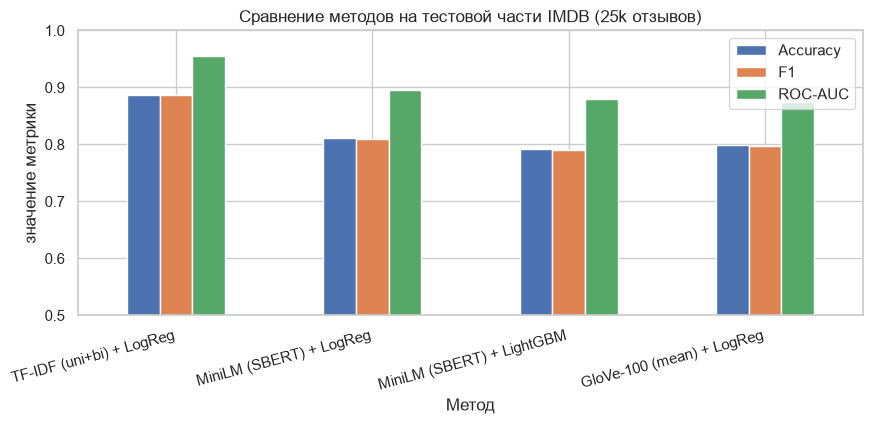

Рисунок сохранён: src\reports\figures\lab4_method_comparison.png


In [12]:
fig, ax = plt.subplots(figsize=(9, 4.4))
comparison.set_index('Метод')[['Accuracy', 'F1', 'ROC-AUC']].plot.bar(
    ax=ax, color=['#4C72B0', '#DD8452', '#55A868'])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel('значение метрики')
ax.set_title('Сравнение методов на тестовой части IMDB (25k отзывов)')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
save_fig('lab4_method_comparison')

## 8. Снижение размерности и визуализация (PCA → t-SNE / UMAP)

Для визуализации берём **сбалансированную подвыборку 5000 отзывов** (2500 positive / 2500 negative) и
применяем к эмбеддингам цепочку **PCA до 50 компонент → t-SNE и UMAP (2D)**. Строим scatter-plot с цветовой
кодировкой классов для лучшего метода (MiniLM) и для статических GloVe-векторов, а разделимость классов
количественно оцениваем через `silhouette_score` (чем выше, тем лучше классы отделены).

In [13]:
VIS_PER_CLASS = 2500


def balanced_indices(labels, per_class, seed=SEED):
    """Индексы сбалансированной подвыборки по классам."""
    rng = np.random.RandomState(seed)
    idx = []
    for cls in np.unique(labels):
        cls_idx = np.where(labels == cls)[0]
        idx.append(rng.choice(cls_idx, size=min(per_class, len(cls_idx)), replace=False))
    return np.concatenate(idx)


def reduce_and_plot(name, X, y, tag):
    """PCA(50) -> t-SNE и UMAP; сохранить график и вернуть метрики разделимости."""
    pca = PCA(n_components=50, random_state=SEED)
    X_pca = pca.fit_transform(X)
    evr = float(pca.explained_variance_ratio_.sum())
    print('%s: PCA(50) объясняет %.1f%% дисперсии' % (name, 100 * evr))

    t0 = time.perf_counter()
    X_tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto',
                  random_state=SEED).fit_transform(X_pca)
    print('  t-SNE: %.1f c' % (time.perf_counter() - t0))

    import umap  # ленивый импорт: numba JIT компилируется при первом вызове
    t0 = time.perf_counter()
    X_umap = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                       random_state=SEED).fit_transform(X_pca)
    print('  UMAP: %.1f c' % (time.perf_counter() - t0))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
    for ax, emb, title in ((axes[0], X_tsne, 't-SNE'), (axes[1], X_umap, 'UMAP')):
        ax.scatter(emb[:, 0], emb[:, 1], c=y, cmap='coolwarm', s=6, alpha=0.55)
        ax.set_title('%s — %s' % (title, name))
        ax.set_xlabel('dim 1')
        ax.set_ylabel('dim 2')
    handles = [plt.Line2D([], [], marker='o', ls='', color='#3B4CC0', label='negative (0)'),
               plt.Line2D([], [], marker='o', ls='', color='#B40426', label='positive (1)')]
    fig.legend(handles=handles, loc='lower center', ncol=2)
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    save_fig('lab4_projection_%s' % tag)

    return {'Метод': name,
            'PCA-50 silhouette': silhouette_score(X_pca, y),
            't-SNE silhouette': silhouette_score(X_tsne, y),
            'UMAP silhouette': silhouette_score(X_umap, y),
            'PCA-50 explained var': evr}

Подвыборка: 5000 отзывов (2500 negative / 2500 positive)
MiniLM (SBERT): PCA(50) объясняет 54.5% дисперсии


  t-SNE: 7.5 c


  UMAP: 25.9 c


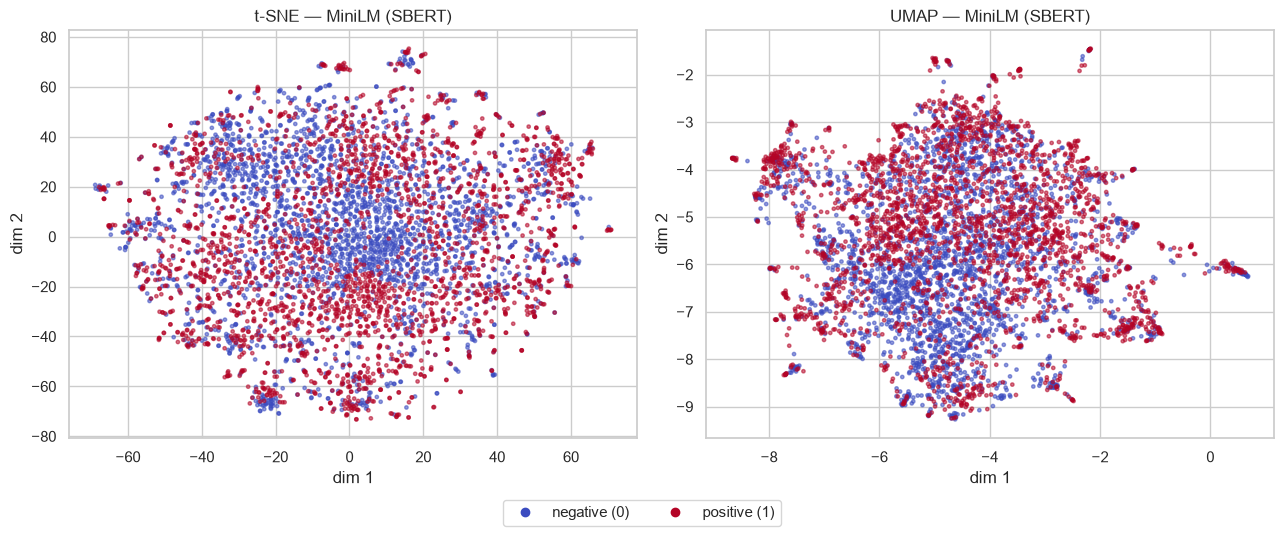

Рисунок сохранён: src\reports\figures\lab4_projection_minilm.png


GloVe-100 (mean): PCA(50) объясняет 88.1% дисперсии


  t-SNE: 6.9 c


  UMAP: 4.2 c


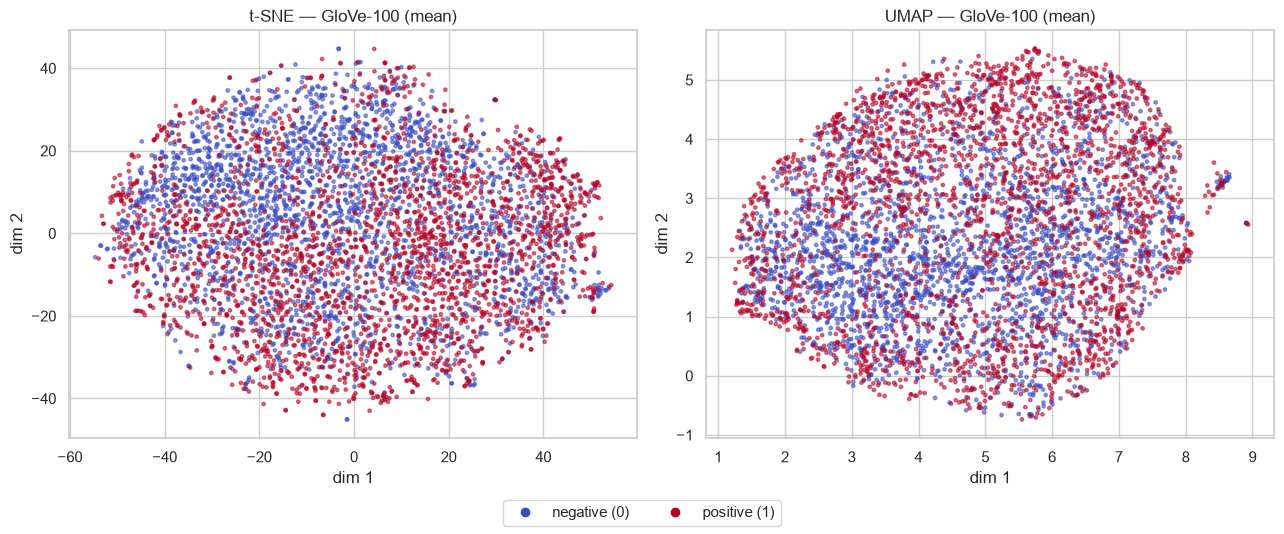

Рисунок сохранён: src\reports\figures\lab4_projection_glove.png


,Метод,PCA-50 silhouette,t-SNE silhouette,UMAP silhouette,PCA-50 explained var
0,MiniLM (SBERT),0.0155,0.0209,0.0285,0.5452
1,GloVe-100 (mean),0.0223,0.0347,0.0290,0.8814


In [14]:
vis_local = balanced_indices(y_train, VIS_PER_CLASS)
y_vis = y_train[vis_local]
print('Подвыборка: %d отзывов (%d negative / %d positive)'
      % (len(vis_local), (y_vis == 0).sum(), (y_vis == 1).sum()))

sil_rows = [reduce_and_plot('MiniLM (SBERT)', Etr_sbert[vis_local], y_vis, 'minilm'),
            reduce_and_plot('GloVe-100 (mean)', Vtr_glove[vis_local], y_vis, 'glove')]

proj_quality = pd.DataFrame(sil_rows)
proj_quality.to_csv(REPORTS_DIR / 'lab4_projection_quality.csv', index=False)
proj_quality.round(4)

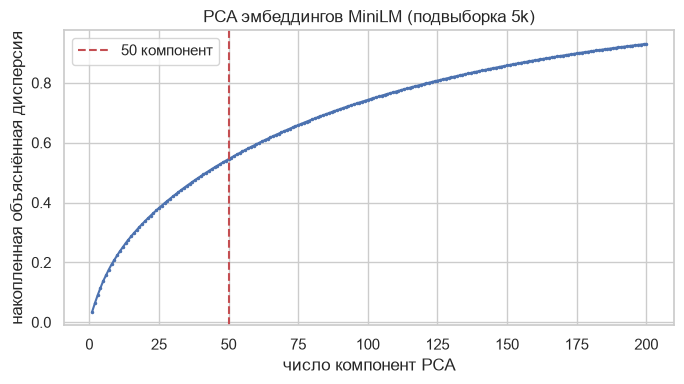

Рисунок сохранён: src\reports\figures\lab4_pca_explained_variance.png
50 компонент объясняют 54.5% дисперсии


In [15]:
pca_full = PCA(n_components=200, random_state=SEED).fit(Etr_sbert[vis_local])
cum_evr = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cum_evr) + 1), cum_evr, marker='.', ms=3, color='#4C72B0')
ax.axvline(50, color='#C44E52', ls='--', label='50 компонент')
ax.set_xlabel('число компонент PCA')
ax.set_ylabel('накопленная объяснённая дисперсия')
ax.set_title('PCA эмбеддингов MiniLM (подвыборка 5k)')
ax.legend()
plt.tight_layout()
save_fig('lab4_pca_explained_variance')
print('50 компонент объясняют %.1f%% дисперсии' % (100 * cum_evr[49]))

In [16]:
import joblib

joblib.dump(tfidf_pipe, MODELS_DIR / 'lab4_imdb_tfidf_logreg.joblib')
joblib.dump(logreg_sbert, MODELS_DIR / 'lab4_imdb_minilm_logreg.joblib')
print('Сохранены модели: lab4_imdb_tfidf_logreg.joblib, lab4_imdb_minilm_logreg.joblib')
print('Сохранены отчёты: lab4_method_comparison.csv, lab4_projection_quality.csv')

Сохранены модели: lab4_imdb_tfidf_logreg.joblib, lab4_imdb_minilm_logreg.joblib
Сохранены отчёты: lab4_method_comparison.csv, lab4_projection_quality.csv


## 9. Выводы

**Лучший результат дал классический TF-IDF + логистическая регрессия** (тест 25k):
ROC-AUC **0.9547**, accuracy **0.8866**. Среди методов на эмбеддингах лучшим оказался
**Sentence-Transformers (`all-MiniLM-L6-v2`) + LogReg** — ROC-AUC 0.8950; GloVe-100 (усреднение) — 0.8750,
LightGBM на MiniLM — 0.8792. Визуализацию делали для лучшего *эмбеддинг*-метода (MiniLM) и дополнительно
для GloVe — как «слабого» представителя статических векторов.

1. **Baseline TF-IDF обошёл нейросетевые эмбеддинги на +0.0597 ROC-AUC.** Причины: длинные отзывы
   обрезаются до 256 токенов (хвост текста теряется); `all-MiniLM-L6-v2` не дообучалась на IMDB и даёт
   «универсальные» эмбеддинги; тональность IMDB во многом выражается прямыми лексическими маркерами
   (`great`, `excellent`, `best` ↔ `worst`, `bad`, `awful`) — их TF-IDF с биграммами ловит идеально,
   а линейная модель обучена под конкретную задачу на 25k примеров.
2. **Статические усреднённые векторы слабее всех** (GloVe-100: ROC-AUC 0.8750): усреднение теряет порядок
   слов («not good» ≈ «good»). Покрытие словаря GloVe — 99.2% (в корпусе 99 088 слов, нашлось 73 973
   вектора), т.е. проигрыш объясняется именно усреднением, а не нехваткой словаря.
3. **MiniLM > GloVe на +0.0199 ROC-AUC** — контекстные эмбеддинги учитывают контекст и порядок слов.
4. **LogReg > LightGBM на MiniLM** (0.8950 против 0.8792): на плотных 384-мерных «сжатых» признаках
   линейная модель с L2 устойчивее, а бустинг склонен их переобучать/дискретизировать.
5. **Стоимость:** TF-IDF+LogReg — 12 c, GloVe+LogReg — 0.2 c, а кодирование 50k отзывов MiniLM —
   **594 c (train) + 710 c (test) ≈ 22 мин** на CPU (batch 64, обрезка 256 токенов). Поэтому эмбеддинги
   кэшируются в `src/data/interim`: повторный запуск ноутбука проходит за ~2 минуты.
6. **Визуализация (PCA-50 → t-SNE / UMAP):** классы **не образуют компактных разделимых кластеров**,
   `silhouette ≈ 0.015–0.035` для обоих методов. Это ожидаемо — тональность не «острова» в пространстве
   эмбеддингов, а одно относительно слабое направление среди множества семантических (жанр, сюжет,
   актёры, длина отзыва); на scatter-plot красное и синее заметно перемешиваются.
7. **UMAP структурирует чуть лучше t-SNE** (silhouette 0.029 против 0.021 у MiniLM, видны локальные
   сгустки-«поджанры»), но чистого разделения по классам не даёт ни один метод; явных выбросов мало.
8. **PCA-50** объясняет **54.5%** дисперсии у MiniLM (признаки размазаны по многим компонентам) и
   **88.1%** у GloVe (усреднённые векторы живут в низкоразмерном подпространстве).
9. **Визуальная разделимость ≠ качество классификации:** у GloVe silhouette даже чуть выше, чем у MiniLM
   (0.022/0.035 против 0.015/0.021), хотя классификация хуже — линейная модель использует направление,
   которое не проявляется как визуальные кластеры.

**Итог.** Для тональности IMDB выгоднее всего классический TF-IDF + LogReg (быстро, дёшево, точно).
Нейросетевые эмбеддинги (`all-MiniLM-L6-v2`) без дообучения чуть уступают по качеству, но дают плотное
универсальное представление текста. Визуализация показала, что тональность — не «кластеры», а тонкое
направление в семантическом пространстве.

In [17]:
print('=== Авто-сводка по результатам прогона ===')
best = comparison.iloc[0]
print('Лучший метод: %s | Accuracy=%.4f  F1=%.4f  ROC-AUC=%.4f'
      % (best['Метод'], best['Accuracy'], best['F1'], best['ROC-AUC']))
base_tfidf = METRICS['TF-IDF (uni+bi) + LogReg']['ROC-AUC']
base_glove = METRICS['GloVe-100 (mean) + LogReg']['ROC-AUC']
sbert = METRICS['MiniLM (SBERT) + LogReg']['ROC-AUC']
print('Прирост MiniLM+LogReg (ROC-AUC): vs TF-IDF %+.4f | vs GloVe %+.4f'
      % (sbert - base_tfidf, sbert - base_glove))
print('\nРазделимость классов (silhouette: PCA-50 / t-SNE / UMAP):')
for _, r in proj_quality.iterrows():
    print('  %-20s %.3f / %.3f / %.3f'
          % (r['Метод'], r['PCA-50 silhouette'], r['t-SNE silhouette'], r['UMAP silhouette']))

=== Авто-сводка по результатам прогона ===
Лучший метод: TF-IDF (uni+bi) + LogReg | Accuracy=0.8866  F1=0.8872  ROC-AUC=0.9547
Прирост MiniLM+LogReg (ROC-AUC): vs TF-IDF -0.0597 | vs GloVe +0.0199

Разделимость классов (silhouette: PCA-50 / t-SNE / UMAP):
  MiniLM (SBERT)       0.015 / 0.021 / 0.029
  GloVe-100 (mean)     0.022 / 0.035 / 0.029
